# *Прогнозирование медицинских расходов*
## О проекте
_Учебный проект по линейной регрессии на датасете Medical Cost Personal._
_Цель: предсказать индивидуальные медицинские расходы на основе демографических и поведенческих факторов._
## Данные
- Источник: Kaggle — Medical Cost Personal Dataset
- Признаки: age, sex, bmi, children, smoker, region
- Целевая переменная: charges (медицинские расходы, USD)
## План работы
1. EDA - разведочный анализ данных
2. Кодирование категориальных признаков (OneHotEncoding)
3. Обучение линейной регрессии
4. Оценка метрик (MAE, RMSE, R²)
5. Анализ остатков
6. Выводы и обоснование следующих шагов

In [20]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
# sklearn - препроцессинг (для категориальных признаков и масштабирования)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
# сохранение модели
from joblib import dump, load


### Загрузка данных

In [21]:
df = pd.read_csv('data/insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [23]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [24]:
df.shape

(1338, 7)

In [25]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [26]:
df.duplicated().sum()

np.int64(1)

In [27]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


### EDA - разведочный анализ
#### *Распределение целевой переменной (charges)*

<Axes: xlabel='charges', ylabel='Count'>

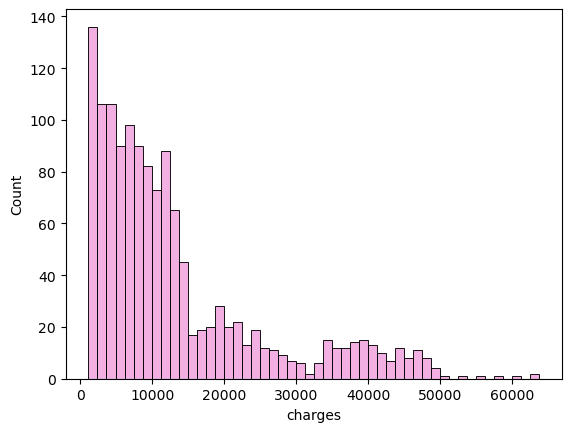

In [42]:
sns.histplot(df['charges'], bins = 50, color = '#ED96D7')


**1. Форма распределения**

*Бимодальное - два пика: основной около 0–5000 и второй около 30 000-40 000*

*Скошено вправо - хвост тянется до 60 000+*

**2. Что это подтверждает**

*Среднее (13 270) > медианы (9 382) - это признак правой скошенности*

*Большинство пациентов платят мало, но есть группа с очень высокими расходами*

**3. Гипотеза**

*Второй пик - возможно, курящие пациенты*

*Проверим на следующем графике (boxplot по smoker)*

#### Расходы в зависимости от курения (smoker)

<Axes: xlabel='smoker', ylabel='charges'>

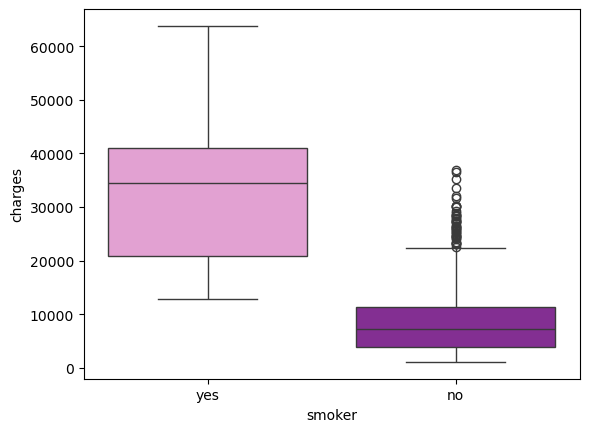

In [58]:
sns.boxplot(data=df, x='smoker', y='charges', hue='smoker', palette = ['#ED96D7', '#8E1EA2'])

#### Вывод: расходы vs smoker
- *Медиана расходов курящих (≈32 000) в 4 раза выше медианы некурящих (≈7 300).*
- *Гипотеза подтверждена: второй пик на гистограмме - это курящие.*
- *У некурящих есть выбросы до ~37 000 - вероятно, есть другие факторы (например, высокий BMI).*
- *`smoker` - сильнейший предиктор в датасете.*

#### Расходы в зависимости от возраста (age)

<Axes: xlabel='age', ylabel='charges'>

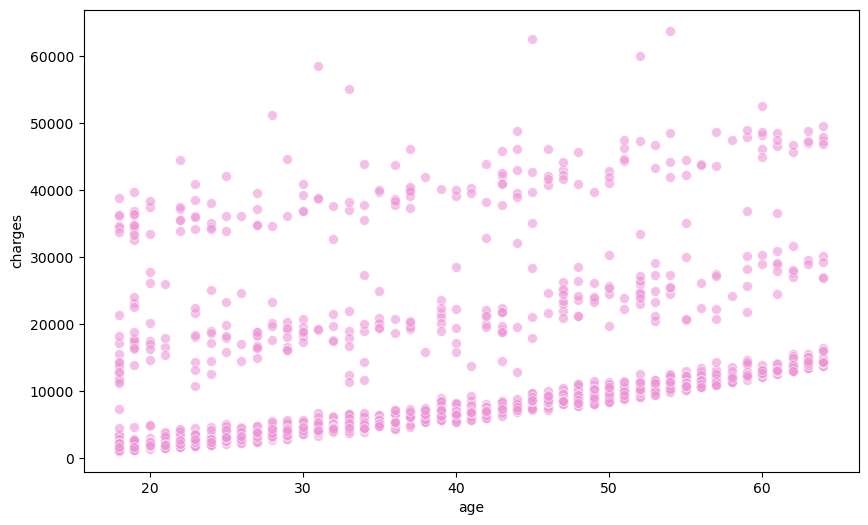

In [41]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data = df, x = 'age', y = 'charges', alpha=0.6, color = '#ED96D7' , s = 50)

#### Вывод: расходы vs age

- *Связь возраста с расходами слабая, но положительная.*
- *На графике видна слоистость - намёк на скрытую группировку.*
- *Гипотеза: полосы соответствуют курящим и некурящим (подтверждено boxplot).*
- *Значит, возраст - не главный предиктор. Основной вклад вносит smoker.*

#### Расходы vs BMI с учётом курения

<Axes: xlabel='bmi', ylabel='charges'>

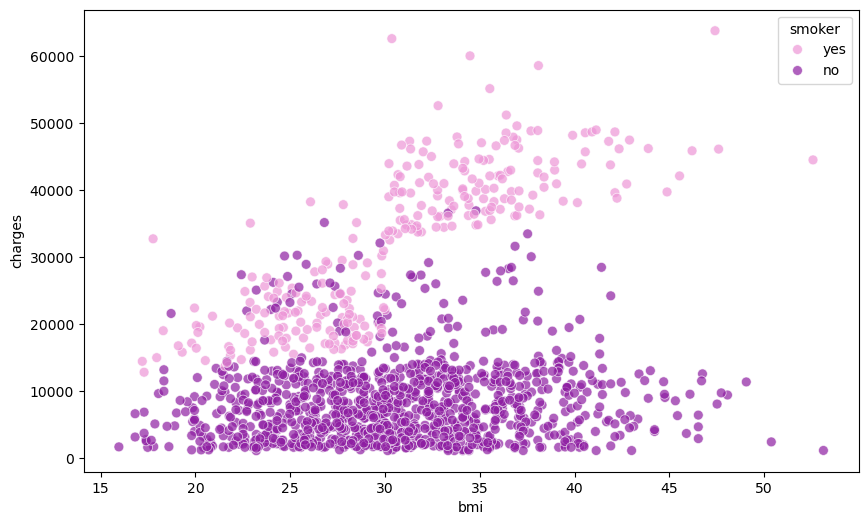

In [53]:
plt.figure(figsize=(10,6))
sns.scatterplot(data = df, x = 'bmi', y = 'charges', hue = 'smoker', alpha = 0.7, s = 50, palette = ['#ED96D7', '#8E1EA2'])

#### Вывод: расходы vs BMI × smoker
- *На графике видны **два облака**: курящие и некурящие.*
- *У некурящих связь BMI с расходами **слабая**.*
- *У курящих связь **сильная**: с ростом BMI расходы резко растут.*
- *Это **взаимодействие** (interaction) - эффект BMI зависит от курения.*
- *Что это значит для модели: обычная линейная регрессия без взаимодействия **не сможет** описать* *обе группы одной линией. Понадобится дополнительный признак `smoker × bmi`.*

#### Расходы vs пол (sex)


<Axes: xlabel='sex', ylabel='charges'>

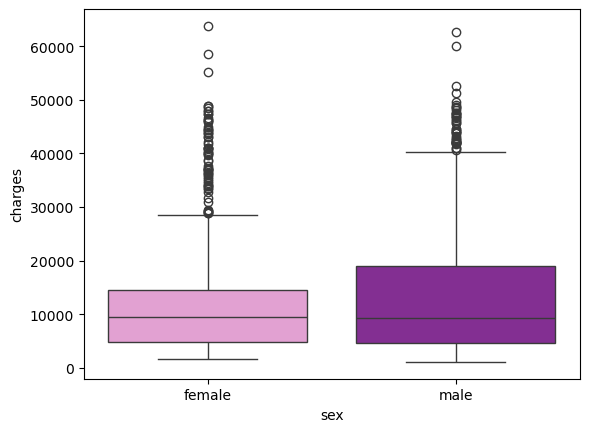

In [56]:
sns.boxplot(data=df, x='sex', y='charges', hue='sex', palette = ['#ED96D7', '#8E1EA2'])


#### Вывод: расходы vs sex
- *Медианы расходов у мужчин и женщин практически одинаковые (~9 000).*
- *IQR у мужчин шире - разброс «типичных» расходов больше.*
- *Пол - слабый предиктор. В модель можно включать, но эффект ожидается минимальный.*

#### Расходы vs регион (region)


<Axes: xlabel='region', ylabel='charges'>

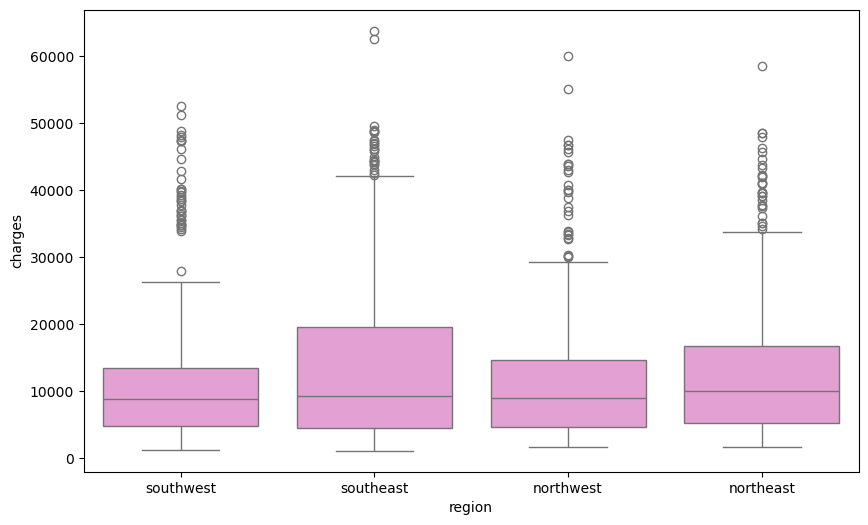

In [66]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='region', y='charges', color = '#ED96D7')

#### Вывод: расходы vs region
- *Медианы во всех регионах практически одинаковые - различия в пределах шума.*
- *Визуально графики неразличимы.*
- *Регион - **неинформативный признак** для предсказания расходов.*
- *В модель можно включить (не повредит), но значимого вклада не ждём.*

#### Корреляционная матрица

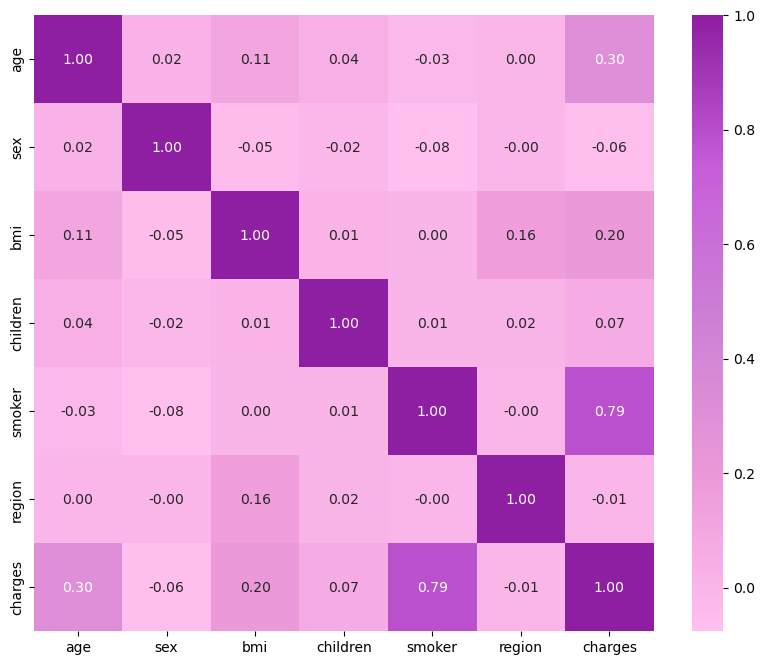

In [79]:
from matplotlib.colors import LinearSegmentedColormap
my_colors = ['#ffc0ef', '#ec99d8', '#cc81d5', '#c75eda', '#8e1ea2']
my_cmap = LinearSegmentedColormap.from_list('pink_purple', my_colors)
df_corr = df.copy()
df_corr['sex'] = df_corr['sex'].map({'male': 0, 'female': 1})
df_corr['smoker'] = df_corr['smoker'].map({'no': 0, 'yes': 1})
df_corr['region'] = df_corr['region'].map({'northeast': 0, 'northwest': 1, 'southeast': 2, 'southwest': 3})
plt.figure(figsize=(10, 8))
sns.heatmap(df_corr.corr(), annot=True, cmap=my_cmap, fmt='.2f')
plt.show()

#### Вывод: корреляционная матрица

- *`smoker` имеет **сильнейшую** связь с charges (0.79).*
- *`age` (0.30) и `bmi` (0.20) - умеренные, но заметные.*
- *`children`, `sex`, `region` - практически нулевые (−0.06 … 0.07).*
- *Мультиколлинеарности между признаками нет (все взаимные корреляции < 0.2). Все признаки можно включать в модель.*
- ***Важно:** корреляция не видит взаимодействия `bmi × smoker`. Реальный эффект BMI для курящих не отражается в общем коэффициенте.*

### Общий вывод по EDA

**1. Форма целевой переменной (`charges`).**
*Распределение бимодальное - два пика. Скошено вправо: среднее (13 270) заметно больше медианы (9 382). Это значит, что большинство пациентов платят мало, но есть группа с очень высокими расходами.*

**2. Главный признак.**
*`smoker` - доминирующий предиктор. Медиана расходов курящих (≈32 000) в 4 раза выше медианы некурящих (≈7 300). Корреляция с `charges` = 0.79.*

**3. Взаимодействие `bmi × smoker`.**
*На scatterplot видно: у некурящих связь BMI с расходами слабая, у курящих - сильная положительная. То есть эффект BMI **зависит** от курения. Обычная линейная регрессия без дополнительного признака `smoker × bmi` этот эффект не уловит.*

**4. Слабые признаки.**
*`age` (0.30) и `bmi` (0.20) - умеренные, но заметно слабее `smoker`.*
*`children`, `sex`, `region` - практически нулевые.*
*Мультиколлинеарности между признаками нет — все взаимные корреляции < 0.2.*

**5. Вывод для модели.**
*Включаем все признаки: `age`, `sex`, `bmi`, `children`, `smoker`, `region`. Ограничение линейной регрессии: она предполагает аддитивность (эффект каждого признака суммируется). Взаимодействие `bmi × smoker` она не увидит — это отразится в остатках. Для улучшения нужно добавить признак `smoker × bmi` (и, возможно, `age²`).*